# 02 · Identification : construire le traitement et le pool de contrôle avant d'estimer

Le design prime sur l'algorithme. Ce notebook pose les hypothèses qui rendent un contrefactuel causal, puis
construit les deux objets que les données ne contiennent pas : les **campagnes** (fenêtres de traitement
détectées dans `onpromotion`) et le **registre de donneurs** (séries de contrôle admises par des règles, pas
par leur ajustement). Les règles sont celles de `plan.md`, fixées avant les résultats ; le nombre de campagnes
qui y survivent est le premier résultat du projet.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyArrowPatch

from novaretail import viz
from novaretail.campaigns import DetectionRule, active_days, detect_unit
from novaretail.data import RESULTS
from novaretail.donors import SUBSTITUTION_EDGES, RegistryRule, eligible_donors, pool_units, registry_report
from novaretail.workspace import load_world

viz.setup()
export = viz.exporter("../figures")
w = load_world()
det = pd.read_parquet(RESULTS / "campaigns.parquet")
rep = json.loads((RESULTS / "campaigns.json").read_text())

## 1. Les hypothèses, et ce que chaque test peut voir

**Intuition.** Le contrefactuel est une prévision des ventes sans campagne, apprise sur la pré-période à partir
de séries de contrôle. Trois hypothèses le rendent causal, aucune n'est testable par l'ajustement :

| Hypothèse | Ce qui la viole ici | Qui peut le voir |
|---|---|---|
| La date de campagne est « comme aléatoire » sachant le passé | une campagne lancée *parce que* les ventes baissaient | placebo dans le temps (partiellement : tendance propre) |
| Les contrôles ne sont pas affectés (SUTVA) | cannibalisation d'une famille substitut, halo sur un complément | placebo dans l'espace, isolation ; **pas** le placebo dans le temps |
| La relation contrôles ↔ cible persiste après la date | changement d'assortiment, rupture au moment de la campagne | rien avant coup ; la réconciliation de marge, après |

La veille a mesuré ces angles morts sur panels à vérité connue : un contrôle cannibalisé biaise l'effet de
+26 % avec un placebo dans le temps **vert**. D'où le registre : exclure par construction ce qui peut interagir.

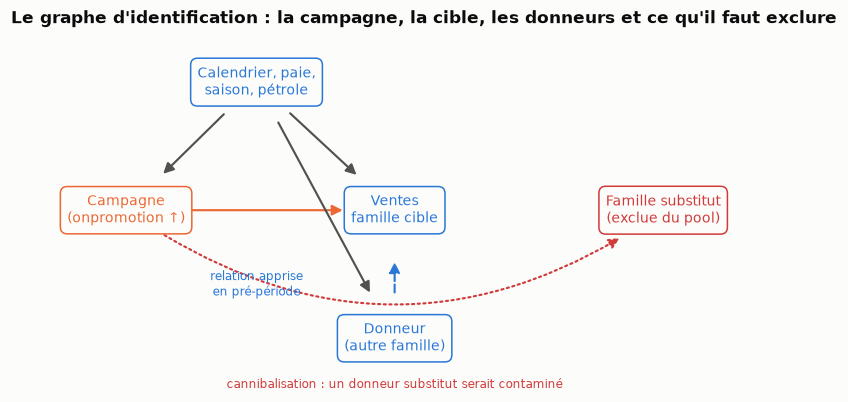

In [2]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.set_xlim(0, 10)
ax.set_ylim(0, 5)
ax.axis("off")
nodes = {"promo": (1.5, 2.5, "Campagne\n(onpromotion ↑)"), "y": (5, 2.5, "Ventes\nfamille cible"),
         "cal": (3.2, 4.3, "Calendrier, paie,\nsaison, pétrole"), "donor": (5, 0.7, "Donneur\n(autre famille)"),
         "sub": (8.5, 2.5, "Famille substitut\n(exclue du pool)")}
for k, (x, y, label) in nodes.items():
    color = viz.ORANGE if k == "promo" else (viz.CRITICAL if k == "sub" else viz.BLUE)
    ax.text(x, y, label, ha="center", va="center", fontsize=9, color=color,
            bbox={"boxstyle": "round,pad=0.5", "fc": viz.base.SURFACE, "ec": color})


def arrow(a, b, color=viz.TEXT_2, style="-", rad=0.0):
    (xa, ya, _), (xb, yb, _) = nodes[a], nodes[b]
    ax.add_patch(FancyArrowPatch((xa, ya), (xb, yb), arrowstyle="-|>", mutation_scale=14, color=color,
                                 linestyle=style, linewidth=1.4, shrinkA=30, shrinkB=34,
                                 connectionstyle=f"arc3,rad={rad}"))


arrow("promo", "y", viz.ORANGE)
arrow("cal", "y")
arrow("cal", "donor")
arrow("cal", "promo")
arrow("donor", "y", viz.BLUE, style="--")
arrow("promo", "sub", viz.CRITICAL, style=":", rad=0.35)
ax.text(3.2, 1.3, "relation apprise\nen pré-période", color=viz.BLUE, fontsize=8, ha="center")
ax.text(5.0, 0.0, "cannibalisation : un donneur substitut serait contaminé", color=viz.CRITICAL, fontsize=8,
        ha="center")
ax.set_title("Le graphe d'identification : la campagne, la cible, les donneurs et ce qu'il faut exclure")
export(fig, "nb02_dag")
plt.show()

## 2. Détecter une campagne dans `onpromotion`

**Intuition.** Une campagne est un saut du compte d'articles promus au-dessus de son fond courant (médiane
glissante sur 60 jours), d'une marge qui dépasse le bruit de Poisson du compte, pendant au moins trois jours.
Elle n'est **mesurable** que si la pré-période de 120 jours est calme (moins de 10 % de jours de campagne,
aucun dans les 30 derniers jours), sans zéro structurel dans la fenêtre, et suivie d'un horizon de 14 jours
pour voir le creux de *pull-forward*. Une campagne qui en suit une autre de trop près voit son horizon tronqué.

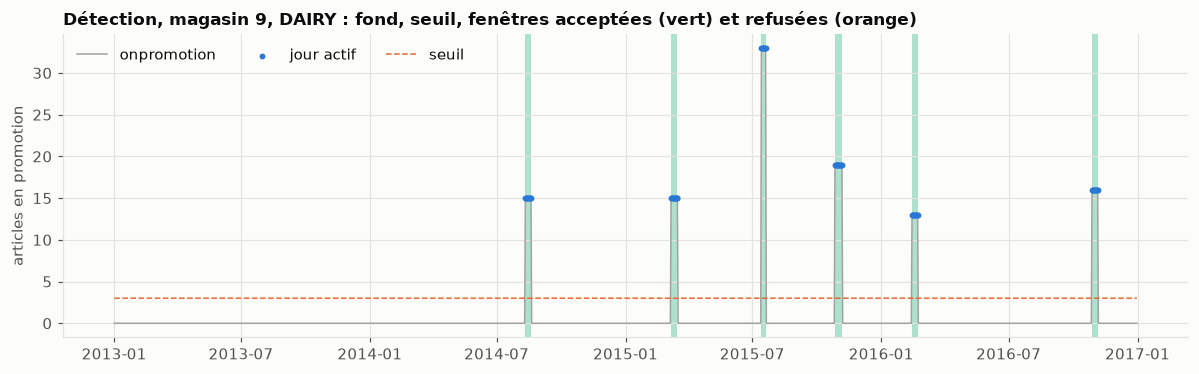

     start        end  length  n_active  n_post  post_truncated  pre_active_share   reason
2014-08-11 2014-08-19       9         9      14           False          0.000000 eligible
2015-03-07 2015-03-16      10        10      14           False          0.000000 eligible
2015-07-14 2015-07-20       7         7      14           False          0.008333 eligible
2015-10-27 2015-11-06      11        11      14           False          0.058333 eligible
2016-02-14 2016-02-22       9         9      14           False          0.091667 eligible
2016-10-28 2016-11-05       9         9      14           False          0.000000 eligible


In [3]:
counts = det[det["eligible"]].groupby(["store_nbr", "family"], observed=True).size()
busy = w.wide_promo.mean()  # prefer a unit with a visible background, so that the threshold has something to track
score = counts.reindex(busy.index).fillna(0) * (busy > busy.median())
unit = tuple(score.idxmax()) if len(counts) else w.units[0]
unit = (int(unit[0]), str(unit[1]))
c, usable = w.wide_promo[unit], w.usable[unit]
rule = DetectionRule()
runs_u = detect_unit(c, usable, rule)
act = active_days(c, rule) & usable
bg = c.shift(1).rolling(rule.background_window, min_periods=14).median().fillna(0)
thr = np.maximum(rule.min_count, rule.ratio * bg + rule.margin + rule.margin_sd * np.sqrt(bg))
fig, ax = viz.plot_campaign_detection(c, act, runs_u, f"Détection, magasin {unit[0]}, {unit[1]} : fond, seuil, "
                                                       "fenêtres acceptées (vert) et refusées (orange)")
ax.plot(thr.index, thr.values, color=viz.ORANGE, linewidth=1, linestyle="--", label="seuil")
ax.legend(loc="upper left", ncol=4)
export(fig, "nb02_detection_unit")
plt.show()
print(runs_u[["start", "end", "length", "n_active", "n_post", "post_truncated", "pre_active_share", "reason"]]
      .head(12).to_string(index=False))

**Exemple.** Sur l'ensemble du panel, la règle rejette beaucoup plus qu'elle n'accepte. Les raisons disent
pourquoi la mesure est rare : la plupart des sauts sont trop courts (bruit du compte) ou tombent dans une
pré-période déjà occupée par d'autres campagnes. C'est le premier résultat : **le nombre de campagnes dont
l'incrémentalité est mesurable par ce design est une petite fraction des jours promus.**

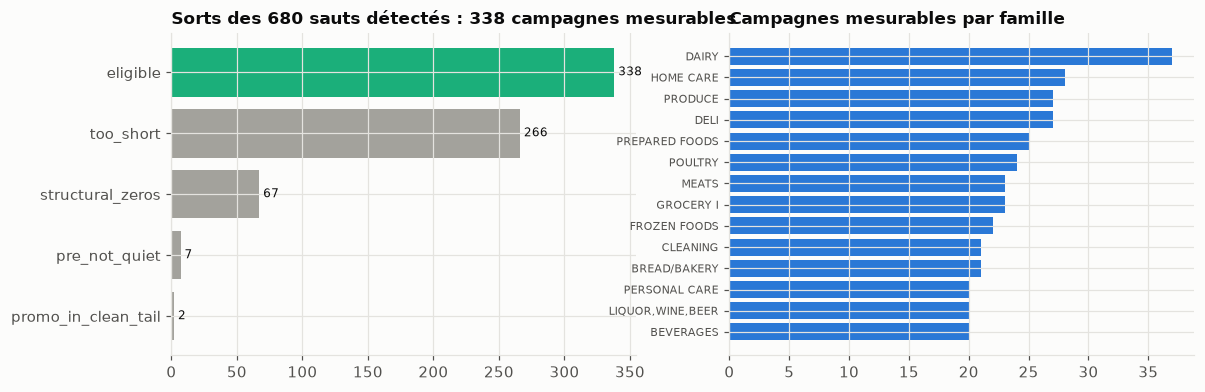

In [4]:
reasons = pd.Series(rep["by_reason"]).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.barh(reasons.index, reasons.values, color=[viz.AQUA if r == "eligible" else viz.MUTED for r in reasons.index])
for i, v in enumerate(reasons.values):
    ax.text(v, i, f" {v}", va="center", fontsize=8)
ax.set_title(f"Sorts des {rep['runs']} sauts détectés : {rep['eligible']} campagnes mesurables")
ax = axes[1]
byfam = pd.Series(rep["by_family_eligible"]).sort_values()
ax.barh(byfam.index, byfam.values, color=viz.BLUE)
ax.set_title("Campagnes mesurables par famille")
ax.tick_params(axis="y", labelsize=7)
export(fig, "nb02_detection_reasons")
plt.show()

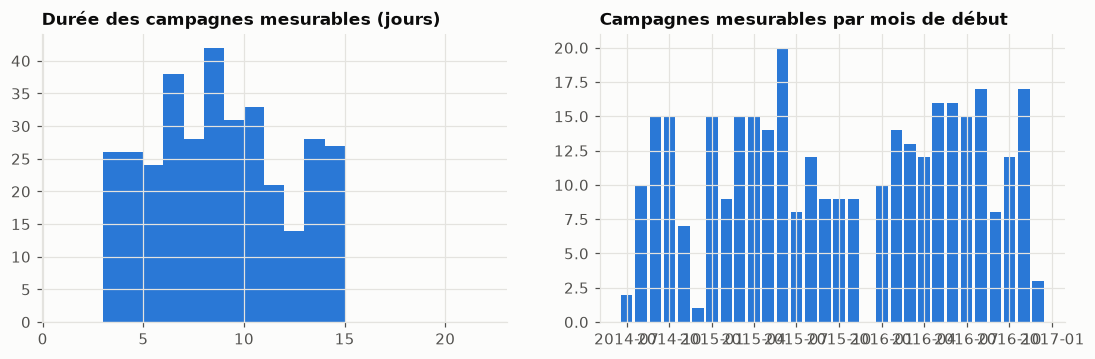

In [5]:
elig = det[det["eligible"]]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].hist(elig["length"], bins=range(1, 23), color=viz.BLUE)
axes[0].set_title("Durée des campagnes mesurables (jours)")
monthly = elig.groupby(elig["start"].dt.to_period("M")).size()
axes[1].bar(monthly.index.to_timestamp(), monthly.values, width=25, color=viz.BLUE)
axes[1].set_title("Campagnes mesurables par mois de début")
export(fig, "nb02_campaign_lengths")
plt.show()

## 3. Le registre de donneurs d'une campagne

**Intuition.** Un donneur est admis par des règles, jamais par son ajustement : une autre famille du même
magasin sans arête de substitution déclarée avec la cible, ou la même famille dans un autre magasin du même
cluster ou de la même province (pas de la même ville : le client peut changer de magasin). Il ne doit pas être
lui-même en campagne de 30 jours avant le début à la fin de l'horizon, ni avoir de zéro structurel dans la
fenêtre, ni être une série de très faible volume. La corrélation de pré-période ne sert qu'à **plafonner**
le pool à 12 ; la sensibilité à ce plafond est mesurée au notebook 03.

In [6]:
camp = elig.sort_values("length", ascending=False).iloc[0]
tab = eligible_donors(w.wide_raw, w.wide_promo, w.usable, w.stores, camp, RegistryRule())
print(f"campagne {camp['campaign_id']} : magasin {camp['store_nbr']}, {camp['family']}, "
      f"du {camp['start'].date()} au {camp['end'].date()} ({camp['length']} jours), fond {camp['background']:.0f}, "
      f"compte moyen {camp['mean_count']:.0f}")
print(registry_report(tab))
print(tab.head(16).to_string(index=False))

campagne 3 : magasin 5, PERSONAL CARE, du 2014-08-11 au 2014-08-24 (14 jours), fond 0, compte moyen 19
{'candidates': 16, 'pool': 12, 'by_reason': {'kept': 12, 'beyond_cap': 3, 'promoted_in_window': 1}, 'by_kind_in_pool': {'same_store_other_family': 10, 'same_family_other_store': 2}}
 store_nbr           family                    kind             reason  corr_pre  in_pool
         5          POULTRY same_store_other_family               kept  0.360037     True
         5             DELI same_store_other_family               kept  0.329714     True
         5        BEVERAGES same_store_other_family               kept  0.286471     True
         1    PERSONAL CARE same_family_other_store               kept  0.246968     True
         5 LIQUOR,WINE,BEER same_store_other_family               kept  0.240649     True
         2    PERSONAL CARE same_family_other_store               kept  0.237108     True
         5     FROZEN FOODS same_store_other_family               kept  0.224958     

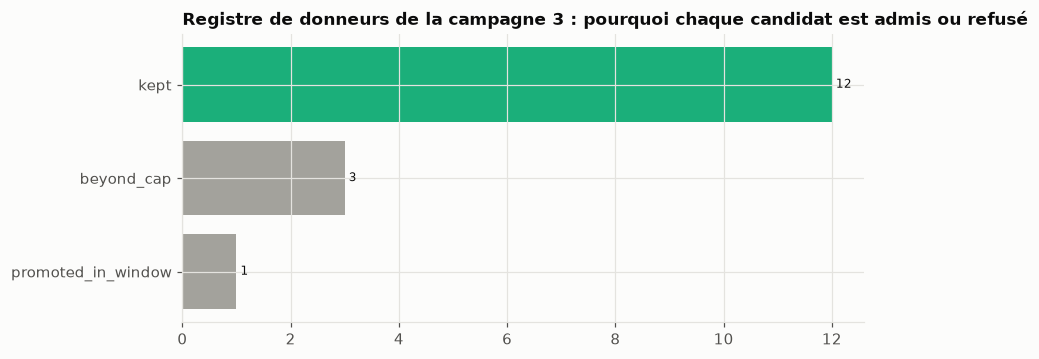

In [7]:
rr = tab["reason"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(rr.index, rr.values, color=[viz.AQUA if r == "kept" else viz.MUTED for r in rr.index])
for i, v in enumerate(rr.values):
    ax.text(v, i, f" {v}", va="center", fontsize=8)
ax.set_title(f"Registre de donneurs de la campagne {camp['campaign_id']} : pourquoi chaque candidat est admis ou refusé")
export(fig, "nb02_registry_reasons")
plt.show()

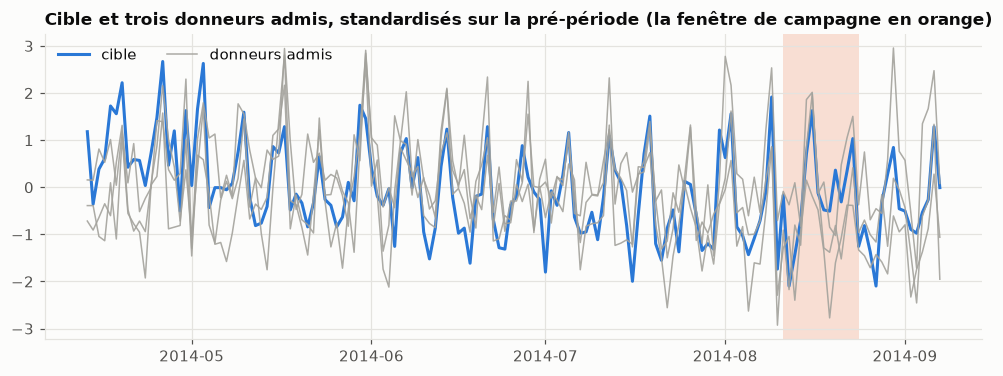

In [8]:
pool = pool_units(tab)[:3]
sl = slice(camp["pre_start"], camp["post_end"])
target = (int(camp["store_nbr"]), str(camp["family"]))
fig, ax = plt.subplots(figsize=(11, 3.6))


def z(s):
    pre = s.loc[: camp["start"]]
    return (s - pre.mean()) / pre.std()


ax.plot(w.wide.loc[sl, target].pipe(np.log1p).pipe(z), color=viz.BLUE, label="cible")
for i, u in enumerate(pool):
    ax.plot(w.wide.loc[sl, u].pipe(np.log1p).pipe(z), color=viz.MUTED, linewidth=1, alpha=0.9,
            label="donneurs admis" if i == 0 else None)
ax.axvspan(camp["start"], camp["end"], color=viz.ORANGE, alpha=0.2, linewidth=0)
ax.set_title("Cible et trois donneurs admis, standardisés sur la pré-période (la fenêtre de campagne en orange)")
ax.legend(loc="upper left", ncol=2)
export(fig, "nb02_target_donors")
plt.show()

**Attention.** Les arêtes de substitution sont déclarées **avant** les résultats, à partir du sens commun du
rayon. Elles sont forcément incomplètes : la cannibalisation réelle entre deux familles non liées resterait
invisible au placebo dans le temps, et c'est le placebo dans l'espace avec isolation (notebook 03) qui a la
charge de l'attraper. Une arête déclarée à tort coûte un donneur ; une arête oubliée coûte un biais.

arêtes déclarées : 24


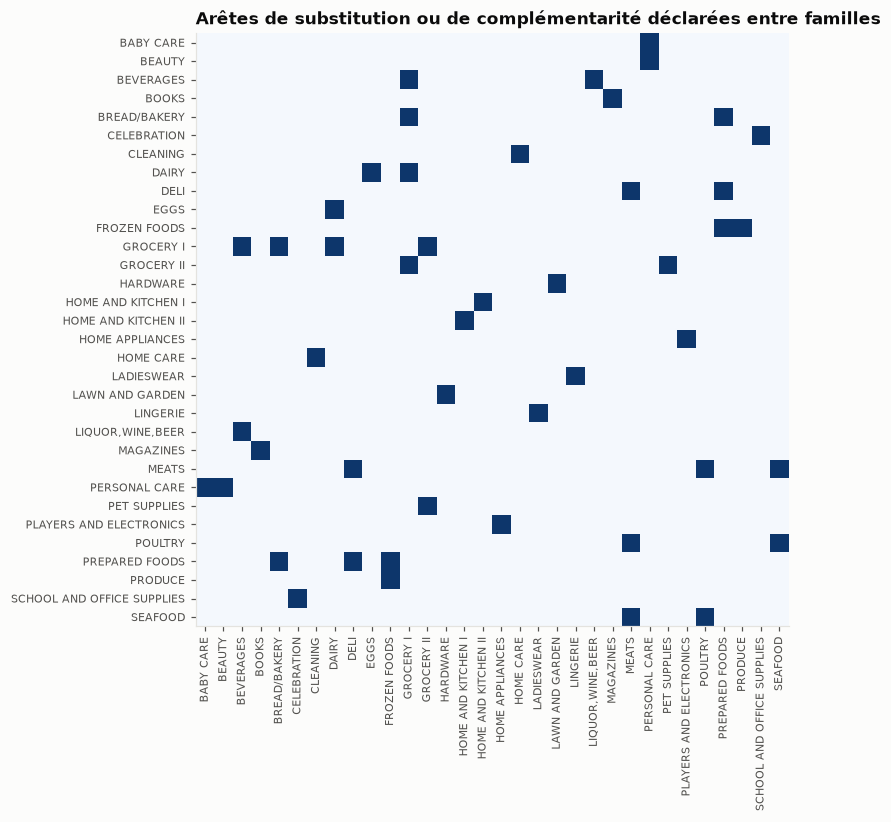

In [9]:
print("arêtes déclarées :", len(SUBSTITUTION_EDGES))
fams = sorted({f for e in SUBSTITUTION_EDGES for f in e})
M = pd.DataFrame(0, index=fams, columns=fams)
for a, b in SUBSTITUTION_EDGES:
    M.loc[a, b] = M.loc[b, a] = 1
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.imshow(M.values, cmap=viz.base.SEQUENTIAL, vmin=0, vmax=1)
ax.set_xticks(range(len(fams)), fams, rotation=90, fontsize=7)
ax.set_yticks(range(len(fams)), fams, fontsize=7)
ax.grid(False)
ax.set_title("Arêtes de substitution ou de complémentarité déclarées entre familles")
export(fig, "nb02_substitution_edges")
plt.show()

## À retenir

- Le traitement est **construit** : un saut de `onpromotion` au-dessus de son fond, avec une pré-période calme
  et un horizon de *pull-forward*. La plupart des jours promus ne sont pas mesurables par ce design.
- Le pool de contrôle est un **registre** : règles d'exclusion déclarées (substitution, promotion dans la
  fenêtre, zéros structurels, volume), corrélation seulement pour plafonner.
- Le placebo dans le temps ne voit pas la cannibalisation ; le registre la prévient, l'isolation la détecte.